# Saving groundwater, burning later: a natural experiment in Punjab

**Question.** Punjab (2008 ordinance, 2009 Act) and Haryana (2009) banned transplanting rice before mid-June, to save
groundwater: rice planted with the monsoon needs less pumping. A later rice crop is harvested later, and the stubble
burnt between rice harvest and wheat sowing moves later too, towards November, when cooler, calmer air traps smoke
over the plains around Delhi. Did that happen, and can it be pinned on the law?

**Design.** Pakistan's Punjab grows the same rice-wheat rotation in the same climate, seen by the same satellites, with
no such law. Comparing the two before and after 2009 removes what both share (weather, satellite changes). This is a
*difference in differences*; it only works if the two were moving in parallel before the law, which we check.

**Data.** MODIS Terra and Aqua active fires (1 km, daily, 2003-2025, 15 Sep-15 Dec) counted inside each region in
Earth Engine (`src/60_paddy_law_fires.py`); groundwater from GRACE (the south-asia-groundwater project). Figures and
statistics: `src/61_paddy_law_figures.py`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image
R = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
t = pd.read_csv(R / "outputs/paddy_law_fire_timing.csv")
t.pivot(index="year", columns="region", values=["fires", "d50", "share_nov"]).round(2)

fires                                      d50  \
region India: Punjab + Haryana Pakistan: Punjab India: Punjab + Haryana   
year                                                                      
2003                   19628.0           1644.0                   293.0   
2004                   17102.0           1979.0                   296.0   
2005                   30662.0           2655.0                   299.0   
2006                   19937.0           1040.0                   295.0   
2007                   29589.0           1424.0                   297.0   
2008                   26704.0           2239.0                   304.0   
2009                   25171.0           2240.0                   301.0   
2010                   24663.0           1964.0                   306.0   
2011                   27183.0           1887.0                   302.0   
2012                   30297.0           2015.0                   307.0   
2013                   24973.0           2513.0                   304.0   
2014                   31046.0           2810.0                   306.0   
2015                   23085.0           2414.0                   308.0   
2016                   33261.0           3184.0                   307.0   
2017                   21624.0           3468.0                   304.0   
2018                   24464.0           3496.0                   309.0   
2019                   18758.0           2989.0                   304.0   
2020                   31709.0           4511.0                   307.0   
2021                   35295.0           7225.0                   311.0   
2022                   19369.0           3994.0                   308.0   
2023                   14848.0           4051.0                   312.0   
2024                    6582.0           3654.0                   315.0   
2025                    5934.0           3707.0                   308.0   

                                      share_nov                   
region Pakistan: Punjab India: Punjab + Haryana Pakistan: Punjab  
year                                                              
2003              324.0                    0.11             0.82  
2004              323.0                    0.12             0.88  
2005              325.0                    0.34             0.90  
2006              325.0                    0.22             0.83  
2007              316.0                    0.24             0.78  
2008              321.0                    0.42             0.84  
2009              320.0                    0.38             0.66  
2010              317.0                    0.58             0.85  
2011              318.0                    0.38             0.72  
2012              315.0                    0.56             0.62  
2013              320.0                    0.48             0.82  
2014              320.0                    0.64             0.78  
2015              317.0                    0.61             0.79  
2016              318.0                    0.52             0.75  
2017              323.0                    0.45             0.66  
2018              310.0                    0.67             0.62  
2019              310.0                    0.49             0.65  
2020              311.0                    0.60             0.64  
2021              309.0                    0.79             0.64  
2022              306.0                    0.64             0.56  
2023              315.0                    0.82             0.75  
2024              308.0                    0.85             0.61  
2025              305.0                    0.73             0.50

`d50` is the day of the year by which half the season's fire pixels had burnt (day 305 = 1 November);
`share_nov` the share burnt from 1 November on.

## Groundwater, burning date and November share together

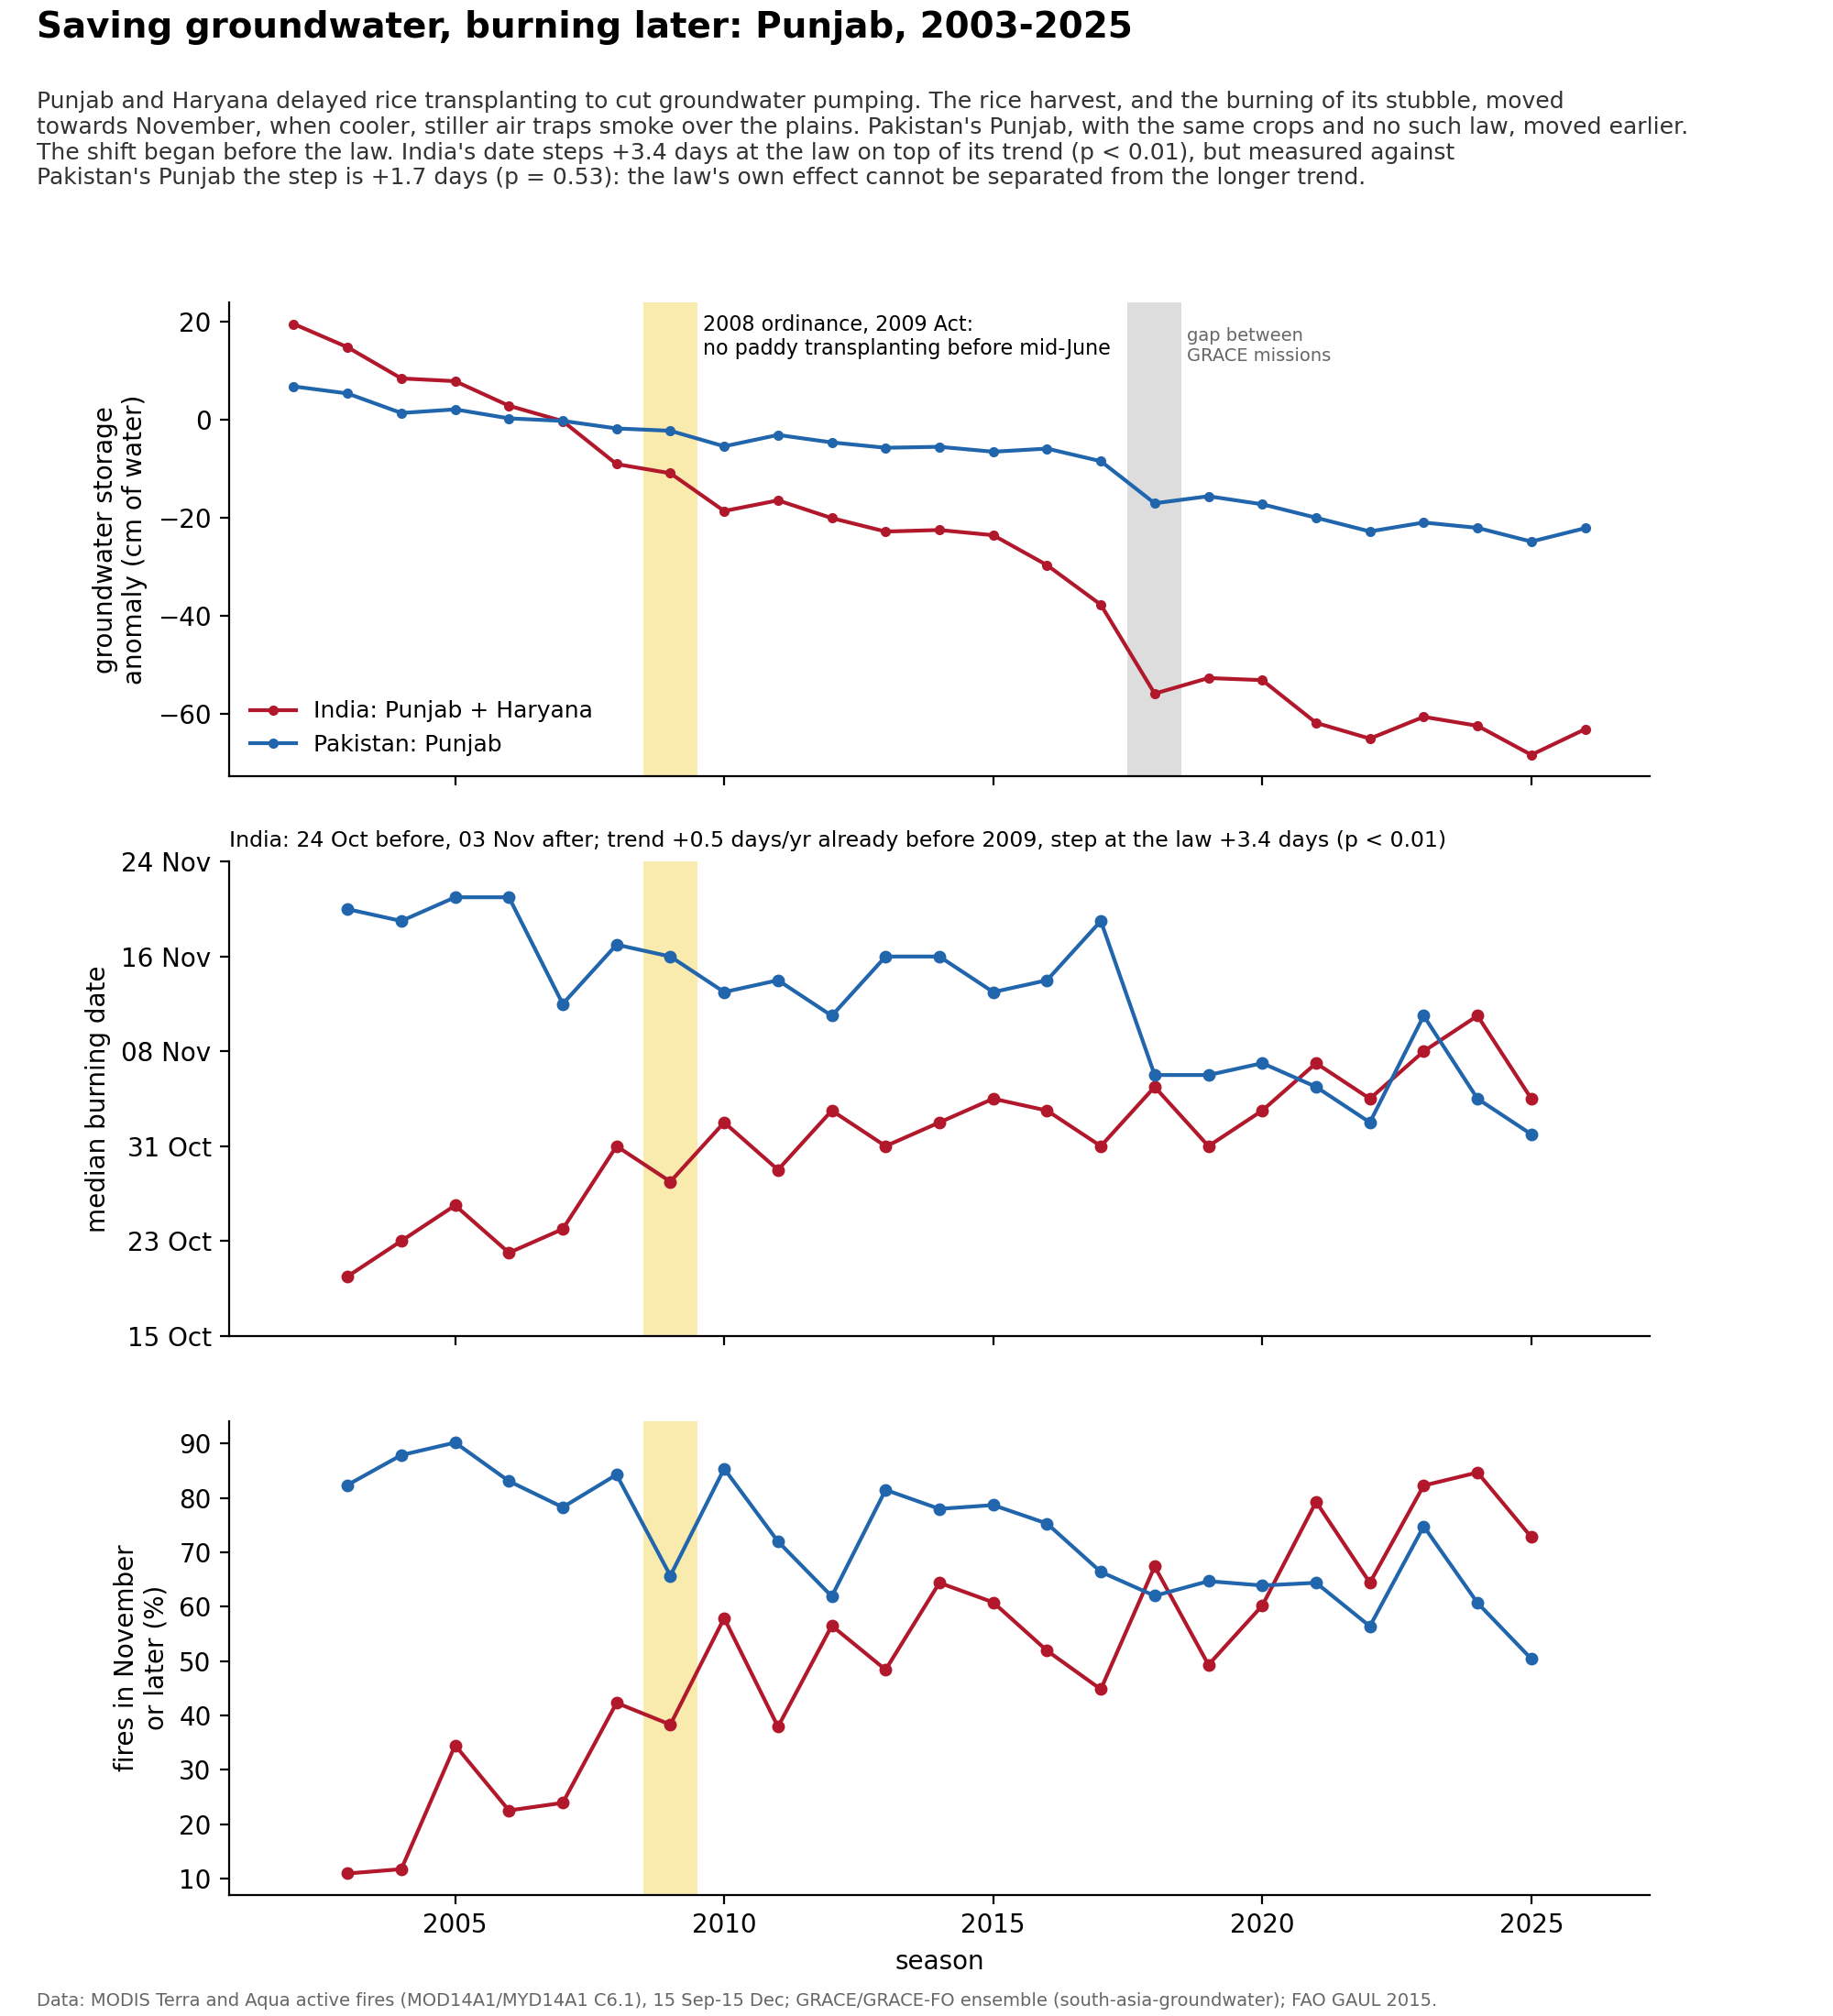

In [2]:
Image(R / "figures/paddy_law_groundwater_fires.png", width=900)

## The burning season, before and after

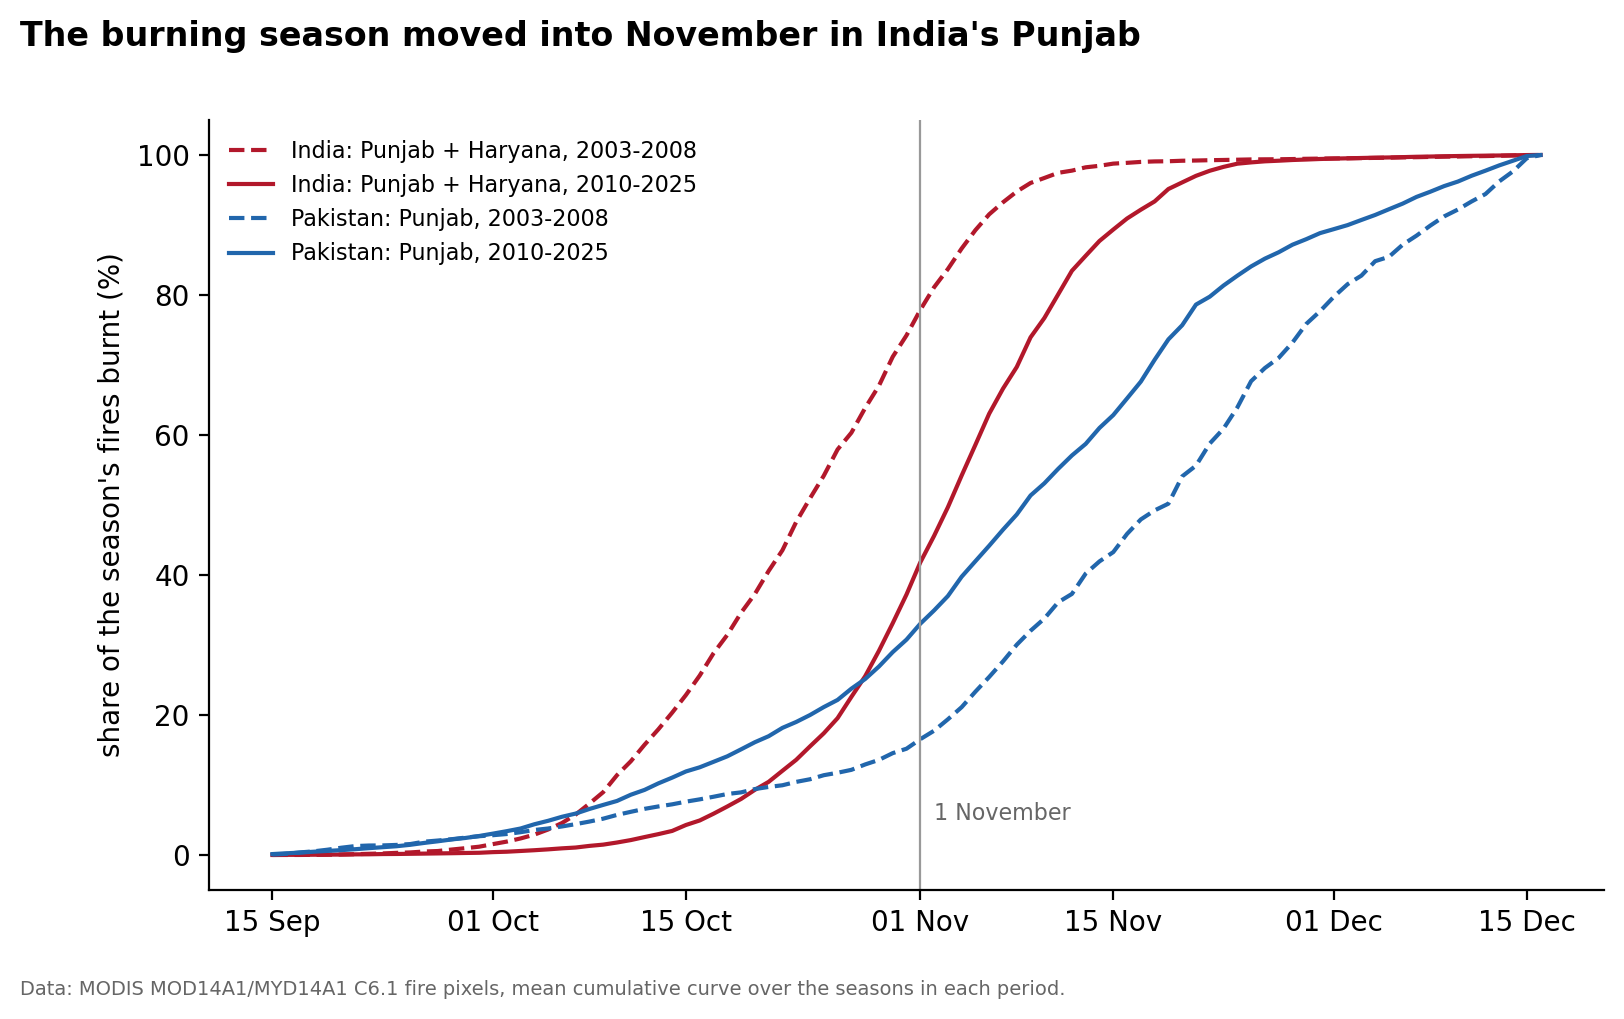

In [3]:
Image(R / "figures/paddy_law_fire_curves.png", width=800)

## The statistics
A segmented regression of the median date on a linear trend plus a step from 2010, with errors that allow for
correlation between neighbouring years (HAC). The key line is the last: the India-minus-Pakistan gap.

In [4]:
pd.read_csv(R / "outputs/paddy_law_stats.csv").round(2)

,series,median_day_2003_2008,median_day_2010_2025,nov_share_2003_2008,nov_share_2010_2025,trend_days_per_yr,step_2010_days,step_p
0,India: Punjab + Haryana,297.33,307.38,0.24,0.61,0.53,3.39,0.00
1,Pakistan: Punjab,322.33,313.88,0.84,0.68,-0.86,1.72,0.45
2,gap India - Pakistan,-25.00,-6.50,NaN,NaN,1.39,1.67,0.53


## What it means
- **Burning moved into November in India's Punjab and Haryana.** The median date went from about 24 October
  (2003-2008) to about 3 November (2010-2025); the share of fires from November on went from about a quarter to
  about 60 per cent. That is the season when smoke is trapped worst over Delhi and Lahore.
- **The law cannot be cleanly credited.** The date was already moving later by about half a day a year before 2009
  (advisories on later transplanting came earlier). India's own series steps about 3 days at the law, but against
  Pakistan's Punjab the step is small and not significant, and the two regions were not moving in parallel before
  2009 (the gap was already narrowing), which weakens the difference-in-differences.
- **Groundwater kept falling.** GRACE shows Indian Punjab and Haryana losing storage throughout, faster than
  Pakistan's Punjab; the law slowed the loss at best (see the south-asia-groundwater period trends: -4.4, -2.3,
  -2.0 cm/yr in 2002-09, 2010-17, 2018-latest).
- **A trade-off to name plainly:** a groundwater policy shifted air pollution into the worst weeks for smog.
  Better residue management (in-field machines, ex-situ use) breaks the trade-off; fire counts fell sharply in 2025.

**Caveats.** Satellite fire pixels miss small or brief fires and fires lit after the afternoon overpass (see
`src/03_fire_timing.py`: farmers may now burn later in the day); MODIS counts are comparable across years because the
same two sensors are used throughout. Region boundaries are FAO GAUL 2015.